# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

current_dir = os.path.dirname(os.path.abspath("Incremental-Learning-MycroftMinds"))
parent_dir = os.path.dirname(current_dir)
# Insert the parent directory at the beginning of sys.path if it's not already there.
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

## Import external libs and internal models

In [2]:
import time
from typing import Optional, Tuple, Dict, Any, List

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
#from river.ensemble import BaggingRegressor, SRPRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
#from river.drift.binary import DDM, EDDM
from src.bagging import ARFRegressorFODT
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.trees import fastodt
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_splits_seq_fit_predict

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

In [4]:
HOURLY = True

In [5]:
# Measure loading time
start_time = time.time()

# Load data
if HOURLY:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_hourly_wfv', use_numpy=True)
    features = ['time', 'device_id', 'hour', 'weekday', 'month', 
                 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                 'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                 'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                 'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                 'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                 'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                 'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                 'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                 'powerfactor3_lag_1h', 'powerfactor3_lag_24h']
else:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='8_dev_5_min_wfv', use_numpy=True)
    # copy features from dataloader printouts
    features = []

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 7 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 7 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.01 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(554, 43), y=(554,)
First valid split shape: X=(573, 43), y=(573,)

Memory usage:
Train: 5.34 MB
Valid: 1.24 MB
Test: 0.36 MB
Total: 6.95 MB


# Model evaluation

## 5-minutes granularity

### Baseline model (predict previous value)

In [7]:
device_period_metrics = {}
for split in valid:
    for device_id in set(split[0][:, 1]):  # Assuming device_id is in the second column
        X_valid, y_valid = get_device_data(split, device_id=device_id)
        y_pred = y_valid.shift(1)
        y_pred.iloc[0] = y_valid.iloc[0]
        
        device_metrics = calculate_metrics(
            y_valid,
            y_pred,
            device_id,
            f"{X_valid[0, 0]} - {X_valid[-1, 0]}", 
            verbose=True
            )
        
        if device_id not in device_period_metrics:
            device_period_metrics[device_id] = []
        device_period_metrics[device_id].append(device_metrics)

all_time_metrics = all_time_aggregation_metrics(device_period_metrics, verbose=True)


Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2600
	MAE: 0.1510
	MAPE: 17.9418%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2600
	MAE: 0.1510
	MAPE: 17.9418%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 0.3596
	MAE: 0.1442
	MAPE: 0.9412%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 0.7703
	MAE: 0.4431
	MAPE: 0.8657%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 1.7066
	MAE: 1.7066
	MAPE: 0.3484%
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2

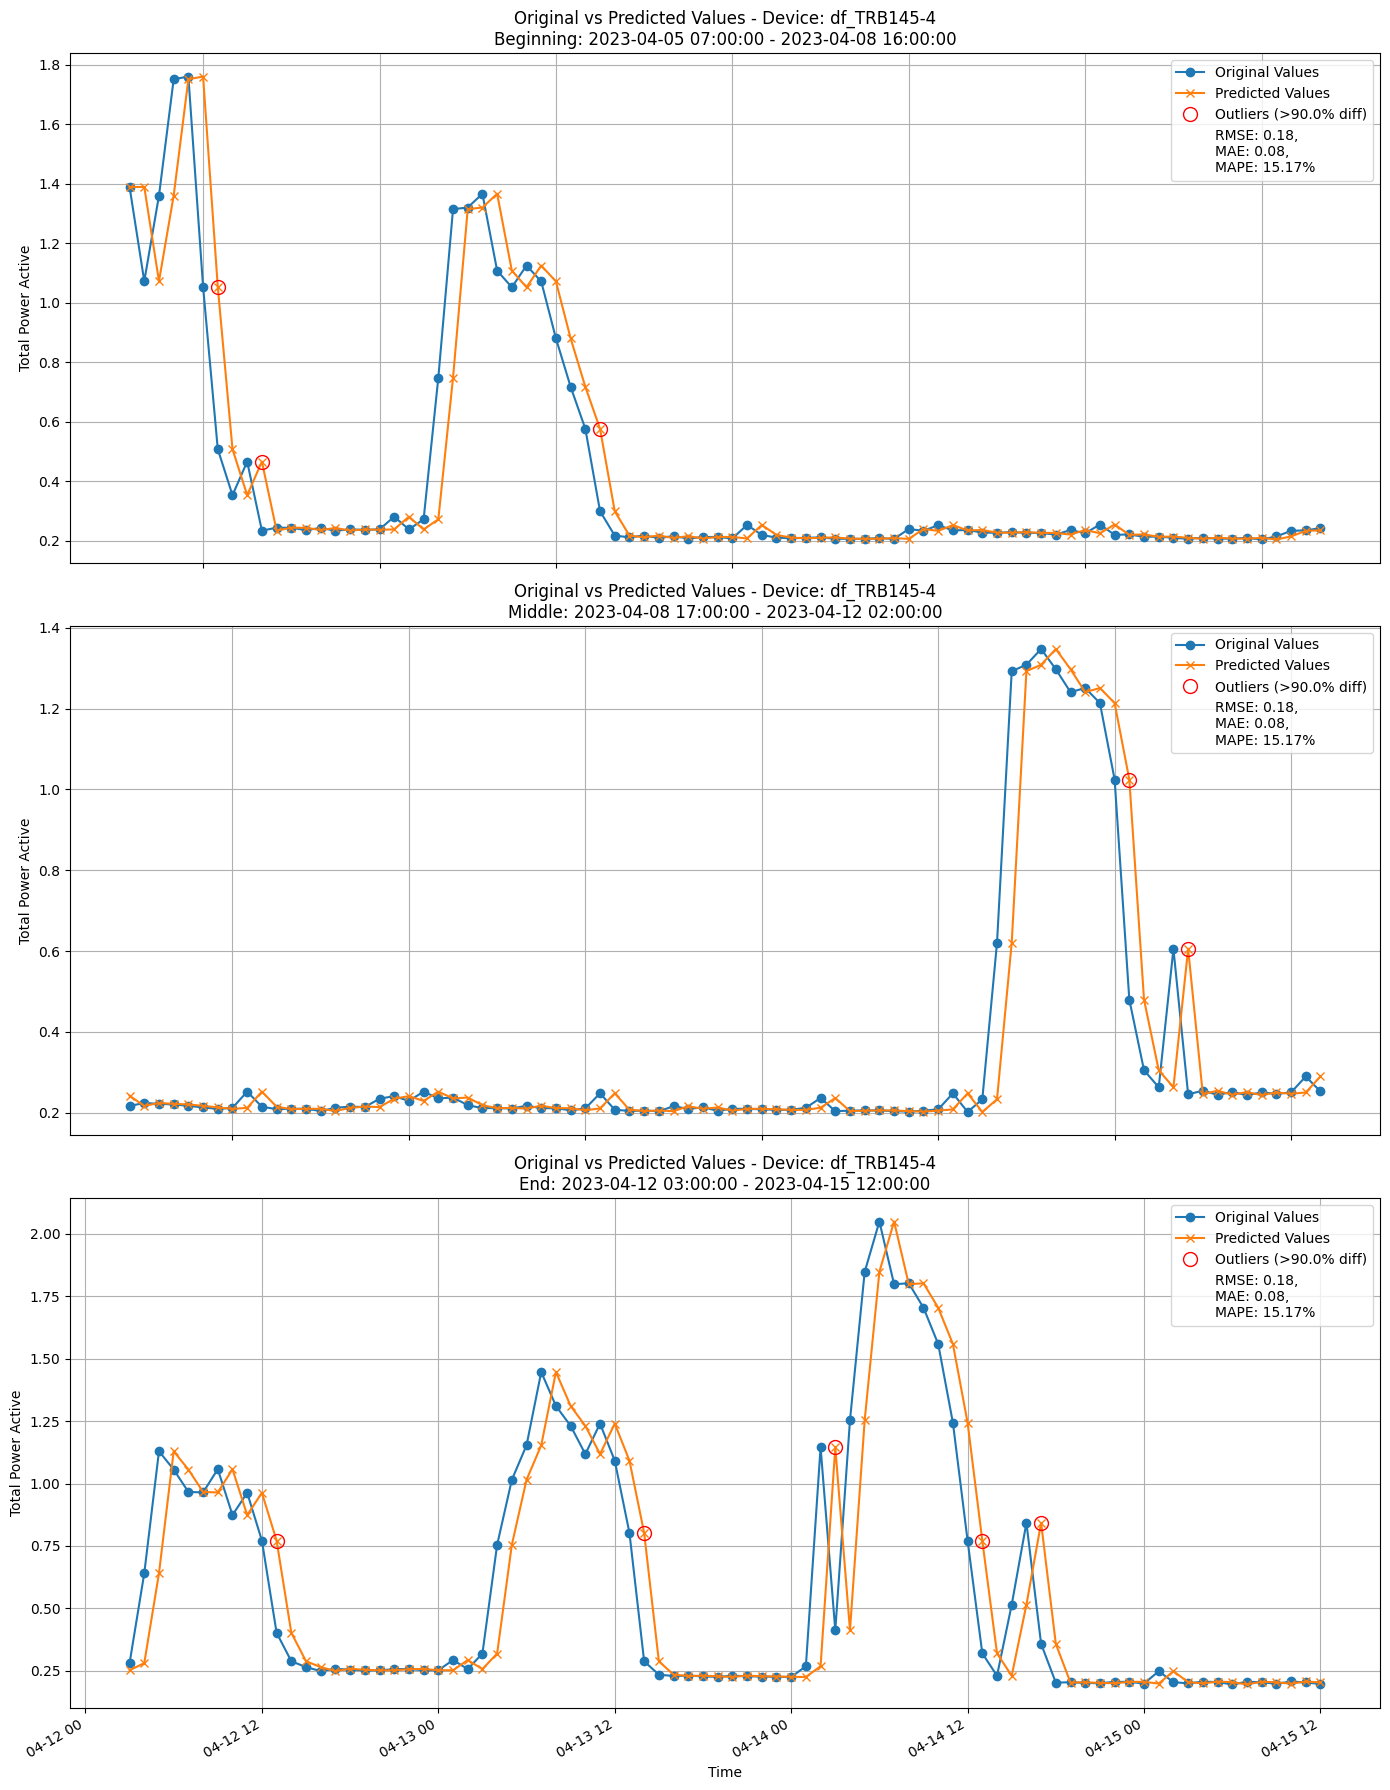

In [8]:
plot_part_predictions(y_valid, y_pred, data_show=100, device_id=device_id)

#### Hourly aggregated predictions with outliers

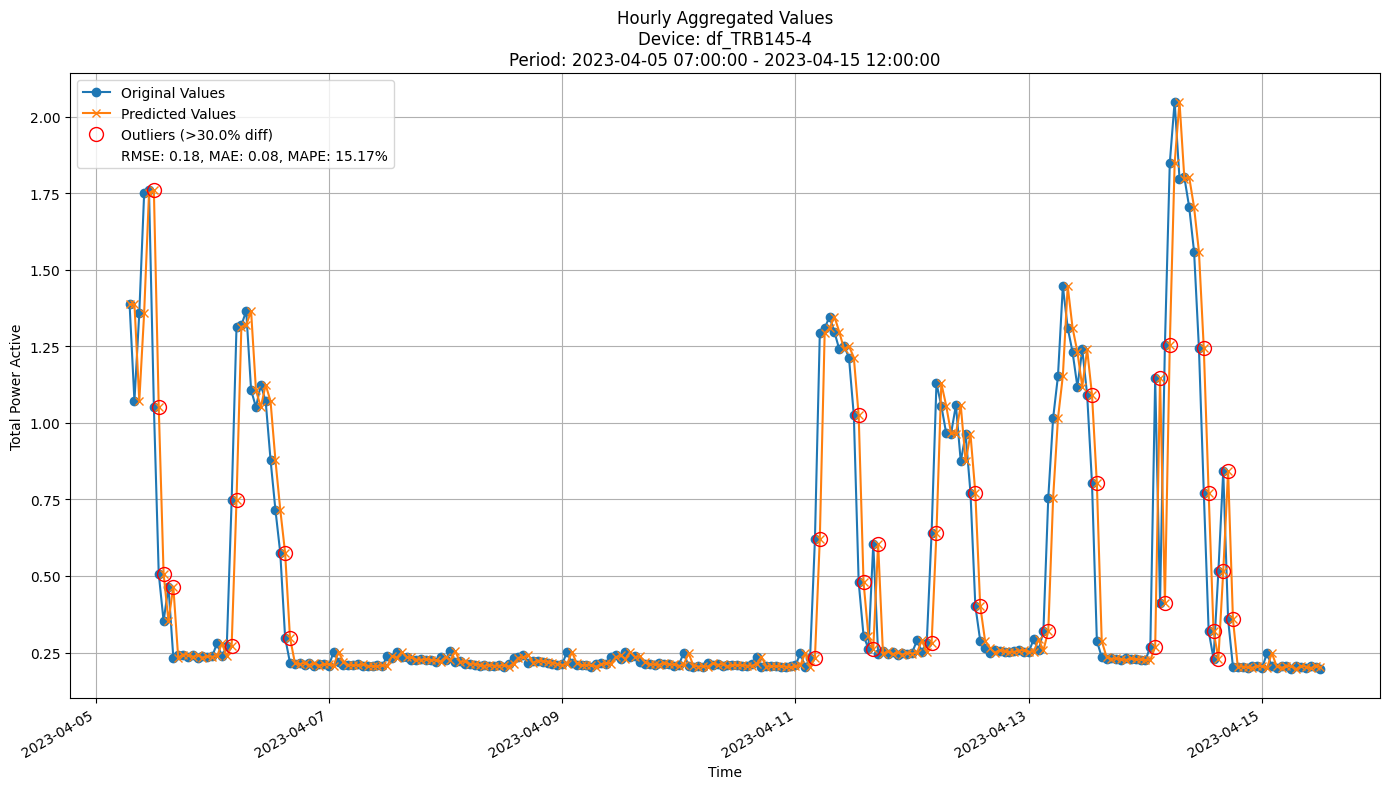

In [9]:
plot_hourly_predictions(
                              y_valid, 
                              y_pred, 
                              device_id=device_id, 
                              outlier_threshold=0.3)

### GBDT

In [10]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.05,
    subsample=0.8,
    max_depth=5,
    random_state=42)

gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_splits_seq_fit_predict(
    model=gbdt,
    train=train,
    valid=valid,
    incremental=False,
    update_freq=update_freq,
    start_split=2,
    end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-12-09 07:00:00

Time: 3.48 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-12-09 08:00:00 to 2022-12-23 08:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-12-23 08:00:00

Time: 3.89 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-12-23 09:00:00 to 2022-12-27 02:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-12-27 02:00:00

Time: 4.16 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2023-01-11 09:00:00 to 2023-01-23 13:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-12-09 08:00:00 - 2023-01-23 13:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2575
	MAE: 0.1693
	MAPE: 42.9519%
--------------------------------------------------
Hourly Metrics:
------------

Processing devices in split 3:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-01-23 13:00:00

Time: 4.18 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-01-23 14:00:00 to 2023-02-06 14:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-02-06 14:00:00

Time: 4.86 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2023-02-06 15:00:00 to 2023-02-16 11:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-01-23 14:00:00 - 2023-02-16 11:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2137
	MAE: 0.1329
	MAPE: 28.9454%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2137
	MAE: 0.1329
	MAPE: 28.9454%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.0205
	MAE: 1.5531
	MAPE

In [11]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_predictions, verbose=True)
print("\n\Valid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_predictions, verbose=True)



Train period metrics:


KeyError: '5_min'

#### Feature importance
[WiP] Right now only for the last split and last device

In [ ]:
feat_imps = sorted(
    zip(features[2:], gbdt.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


#### Training plots
Plot only the last period of predictions

In [ ]:
for device_id in gbdt_train_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_train, y_pred_train, data_show=100, device_id=device_id)
    print("="*25)

In [ ]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

#### Validation plots
Plot only the last period of predictions

In [ ]:
for device_id in gbdt_valid_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_valid = gbdt_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = gbdt_valid_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_valid, y_pred_valid, data_show=100, device_id=device_id)
    print("="*25)

In [ ]:
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = gbdt_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = gbdt_valid_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

### Random Forest model

In [ ]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor(
    n_estimators=150, 
    max_depth=5, 
    random_state=42, 
    n_jobs=-1)

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_splits_seq_fit_predict(
    model=rf, 
    train=train, 
    valid=valid, 
    incremental=False, 
    update_freq=update_freq, 
    start_split=2, 
    end_split=4,  # Use only the third and fourth splits
    verbose=True
)

In [ ]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, verbose=True)
print("\n\Valid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, verbose=True)

#### Training plots
Plot only the last period of predictions

In [ ]:
for device_id in rf_train_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_train, y_pred_train, data_show=100, device_id=device_id)
    print("="*25)


In [ ]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

#### Validation plots
Plot only the last period of predictions

In [ ]:
for device_id in rf_valid_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_valid = rf_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = rf_valid_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_valid, y_pred_valid, data_show=100, device_id=device_id)
    print("="*25)

In [ ]:
for device_id in rf_valid_period_predictions.keys():
    y_valid = rf_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = rf_valid_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

### FastODT

In [ ]:
update_freq = "5m"  # for incremental models put the same as the data frequency to recreate real world scenario
grace_period = 10
split_confidence = 0.05
fodt = fastodt.FastODT(
        depth=20,
        grace_period=grace_period,
        split_confidence=split_confidence,
        option='hf'
    )

fodt_train_period_predictions, fodt_valid_period_predictions, \
fodt_train_period_metrics, fodt_valid_period_metrics = all_splits_seq_fit_predict(
    model=fodt, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=2, 
    end_split=4,  # Use only the third and fourth splits
    verbose=True
)

In [ ]:
print("\n\nTrain period metrics:")
all_time_train_metrics = all_time_aggregation_metrics(fodt_train_period_metrics, verbose=True)
print("\n\Valid period metrics:")
all_time_valid_metrics = all_time_aggregation_metrics(fodt_valid_period_metrics, verbose=True)

#### Training plots
Plot only the last period of predictions

In [ ]:
for device_id in fodt_train_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_train = fodt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = fodt_train_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_train, y_pred_train, data_show=100, device_id=device_id)
    print("="*25)

In [ ]:
for device_id in fodt_train_period_predictions.keys():
    y_train = fodt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = fodt_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

#### Validation plots
Plot only the last period of predictions

In [ ]:
for device_id in fodt_valid_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_valid = fodt_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = fodt_valid_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_valid, y_pred_valid, data_show=100, device_id=device_id)
    print("="*25)

In [ ]:
for device_id in fodt_valid_period_predictions.keys():
    y_valid = fodt_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = fodt_valid_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

### iNcubation Boost

In [ ]:
update_freq = "5m"  # for incremental models put the same as the data frequency to recreate real world scenario
split_confidence_hf = 0.05
n_trees = 5
depth = 20
grace_period = 10
incb = IncubationBoost(
    fastodt.FastODT,
    n_trees,
    incubationMode = "SHIFT_LEFT",
    verbose=True,
    baseLearnerOptions = (depth, grace_period, split_confidence_hf, "hf")
    )

incb_train_period_predictions, incb_valid_period_predictions, \
incb_train_period_metrics, incb_valid_period_metrics = all_splits_seq_fit_predict(
    model=incb, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=2, 
    end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-12-09 07:00:00


  0%|          | 0/1701 [00:00<?, ?it/s]

In [ ]:
print("\n\nTrain period metrics:")
all_time_train_metrics = all_time_aggregation_metrics(incb_train_period_metrics, verbose=True)
print("\n\Valid period metrics:")
all_time_valid_metrics = all_time_aggregation_metrics(incb_valid_period_metrics, verbose=True)

#### Train plots
Plot only the last period of predictions


In [ ]:
for device_id in incb_train_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_train = incb_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = incb_train_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_train, y_pred_train, data_show=100, device_id=device_id)
    print("="*25)


In [ ]:
for device_id in incb_train_period_predictions.keys():
    y_train = incb_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = incb_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

#### Validation plots
Plot only the last period of predictions

In [ ]:
for device_id in incb_valid_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_valid = incb_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = incb_valid_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_valid, y_pred_valid, data_show=100, device_id=device_id)
    print("="*25)

In [ ]:
for device_id in incb_valid_period_predictions.keys():
    y_valid = incb_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = incb_valid_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

## Hourly granularity

### Baseline model (predict previous value)

In [ ]:
device_period_metrics = {}
for split in valid:
    for device_id in set(split[0][:, 1]):  # Assuming device_id is in the second column
        X_valid, y_valid = get_device_data(split, device_id=device_id)
        y_pred = y_valid.shift(1)
        y_pred.iloc[0] = y_valid.iloc[0]
        
        device_metrics = calculate_metrics(
            y_valid,
            y_pred,
            device_id,
            f"{X_valid[0, 0]} - {X_valid[-1, 0]}", 
            verbose=True
            )
        
        if device_id not in device_period_metrics:
            device_period_metrics[device_id] = []
        device_period_metrics[device_id].append(device_metrics)

In [ ]:
all_time_metrics = all_time_aggregation_metrics(device_period_metrics, verbose=True)

#### Validation plots

In [ ]:
plot_hourly_predictions(y_valid, 
                        y_pred, 
                        device_id, 
                        outlier_threshold=0.9)

### GBDT

In [ ]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.01,
    subsample=0.8,
    max_depth=6,
    random_state=42)

gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_splits_seq_fit_predict(
    model=gbdt, 
    train=train, 
    valid=valid, 
    incremental=False, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=False
)

In [ ]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, verbose=True)

#### Feature importance
[WiP] Right now only for the last split and last device

In [ ]:
feat_imps = sorted(
    zip(features[2:], gbdt.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


#### Training plots
Plot only the last period of predictions

In [ ]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=3.0)
# 48, 32, 61

#### Validation plots
Plot only the last period of predictions

In [ ]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Random Forest model

In [ ]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor(
    n_estimators=100, 
    max_depth=4,
    max_features=0.8,
    random_state=42, 
    n_jobs=-1)

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_splits_seq_fit_predict(
    model=rf, 
    train=train, 
    valid=valid, 
    incremental=False, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

In [ ]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, verbose=True)

#### Feature importance
[WiP] Right now only for the last split and last device

In [ ]:
feat_imps = sorted(
    zip(features[2:], rf.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


#### Training plots
Plot only the last period of predictions

In [ ]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

In [ ]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

grace_period = 10
delta = 0.5
max_depth = 10
tau = 0.05

hoef = HoeffdingTreeRegressor(
        max_depth=max_depth,
        grace_period=grace_period,
        delta=delta,
        tau=tau,
        leaf_prediction="mean"
    )

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_splits_seq_fit_predict(
    model=hoef, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

In [ ]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, verbose=True)
print("\n\nValid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, verbose=True)

#### Training plots
Plot only the last period of predictions

In [ ]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=3.0)

#### Validation plots
Plot only the last period of predictions

In [ ]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 10
max_features = 0.8
grace_period = 10
split_confidence = 0.5
depth = 10
tau = 0.01

arf_hf = ARFRegressor(
        n_models=n_models,
        max_features=max_features,
        aggregation_method='median',
        grace_period=grace_period,
        max_depth=depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
    )

arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_splits_seq_fit_predict(
    model=arf_hf,
    train=train,
    valid=valid,
    incremental=True,
    update_freq=update_freq,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

In [ ]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, verbose=True)

#### Training plots
Plot only the last period of predictions

In [ ]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=3.0)

#### Validation plots
Plot only the last period of predictions

In [ ]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
grace_period = 10
split_confidence = 0.5
depth = 20
fodt = fastodt.FastODT(
        depth=depth,
        grace_period=grace_period,
        split_confidence=split_confidence,
        option='hf'
    )

fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_splits_seq_fit_predict(
    model=fodt, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

In [ ]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, verbose=True)

#### Training plots
Plot only the last period of predictions

In [ ]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=3.0)

#### Validation plots
Plot only the last period of predictions

In [ ]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 10
grace_period = 10
aggregation_method = "median"
split_confidence = 0.5
tau = 0.01
max_depth = 40

arf = ARFRegressorFODT(
        n_models=n_models,
        aggregation_method=aggregation_method,
        grace_period=grace_period,
        max_depth=max_depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
    )

arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_splits_seq_fit_predict(
    model=arf,
    train=train,
    valid=valid,
    incremental=True,
    update_freq=update_freq,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

In [ ]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, verbose=True)

#### Training plots
Plot only the last period of predictions

In [ ]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=3.0)

#### Validation plots
Plot only the last period of predictions

In [ ]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
split_confidence_hf = 0.05
n_trees = 10
depth = 20
grace_period = 10
incb = IncubationBoost(
    fastodt.FastODT,
    n_trees,
    incubationMode = "DEFAULT",
    baseLearnerOptions = (depth, grace_period, split_confidence_hf, "hf")
    )

incb_train_period_predictions, incb_valid_period_predictions, \
incb_train_period_metrics, incb_valid_period_metrics = all_splits_seq_fit_predict(
    model=incb, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=2, 
    end_split=4,  # Use only the third and fourth splits
    verbose=True
)

In [ ]:
print("\n\nTrain period metrics:")
all_time_train_metrics = all_time_aggregation_metrics(incb_train_period_metrics, verbose=True)
print("\n\Valid period metrics:")
all_time_valid_metrics = all_time_aggregation_metrics(incb_valid_period_metrics, verbose=True)

#### Train plots
Plot only the last period of predictions


In [ ]:
for device_id in incb_train_period_predictions.keys():
    y_train = incb_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = incb_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=5.)

#### Validation plots
Plot only the last period of predictions

In [ ]:
for device_id in incb_valid_period_predictions.keys():
    y_valid = incb_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = incb_valid_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=0.9)